<a href="https://colab.research.google.com/github/nabeeha-rafi/Social-Media-Sentiment-Engagement-Analysis/blob/main/sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ============================================================
# Daraz Product Reviews Dataset Cleaning and Analysis
# ============================================================

import pandas as pd
import re

# 1. LOAD THE DATASET
file_path = "/content/daraz_products_reviews.csv"
df = pd.read_csv(file_path)

print("Original dataset shape:", df.shape)
print("\nOriginal columns:")
print(df.columns.tolist())

# 2. STANDARDIZE COLUMN NAMES
# Converts columns like 'Spam(1) and Not Spam(0)' to 'spam_1_and_not_spam_0'
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("\nStandardized columns:")
print(df.columns.tolist())

# 3. REMOVE DUPLICATE REVIEWS
# Remove duplicate combinations of product_id and review text
if "product_id" in df.columns and "reviews" in df.columns:
    df = df.drop_duplicates(subset=["product_id", "reviews"], keep="first").copy()

# 4. CLEAN REVIEW TEXT
def clean_text(value):
    """Remove URLs, HTML entities, and unnecessary whitespace."""
    if pd.isna(value):
        return ""

    value = str(value)
    value = re.sub(r"https?://\S+|www\.\S+", "", value)
    value = re.sub(r"&amp;", "&", value)
    value = re.sub(r"<[^>]+>", " ", value)
    value = re.sub(r"\s+", " ", value)

    return value.strip()

if "reviews" in df.columns:
    df["reviews"] = df["reviews"].apply(clean_text)

# 5. PARSE TIMESTAMPS / DATES
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    # Drop records with missing dates if necessary
    df = df.dropna(subset=["date"]).copy()

    # Extract Date-Time Features
    df["day_of_week"] = df["date"].dt.day_name()
    df["month_year"] = df["date"].dt.strftime("%B %Y")
    df["year"] = df["date"].dt.year

# 6. STANDARDIZE RATINGS AND SPAM LABELS
if "rating" in df.columns:
    df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

if "spam_1_and_not_spam_0" in df.columns:
    df["spam_1_and_not_spam_0"] = pd.to_numeric(df["spam_1_and_not_spam_0"], errors="coerce")

# 7. DISPLAY RESULTS
print("\nCleaned dataset shape:", df.shape)
print("\nMissing values in cleaned dataset:")
print(df.isna().sum())

print("\nDataset preview:")
print(df.head())

# 8. EXPORT CLEANED DATASET
df.to_csv("daraz_reviews_cleaned.csv", index=False)
print("\nCleaned file exported successfully to 'daraz_reviews_cleaned.csv'.")


Original dataset shape: (3923, 7)

Original columns:
['Product_ID', 'Date', 'Rating', 'Spam(1) and Not Spam(0)', 'Reviews', 'Sentiment', 'Features']

Standardized columns:
['product_id', 'date', 'rating', 'spam_1_and_not_spam_0', 'reviews', 'sentiment', 'features']

Cleaned dataset shape: (3891, 10)

Missing values in cleaned dataset:
product_id               0
date                     0
rating                   0
spam_1_and_not_spam_0    0
reviews                  0
sentiment                0
features                 0
day_of_week              0
month_year               0
year                     0
dtype: int64

Dataset preview:
            product_id       date  rating  spam_1_and_not_spam_0  \
0  TE111EL1KXNGWNAFAMZ 2019-11-09       1                      0   
1  MI543EL02ACXSNAFAMZ 2016-11-21       5                      0   
2  MI543EL02ACXSNAFAMZ 2018-10-22       2                      0   
3  TE111EL1KXNGWNAFAMZ 2017-10-06       3                      0   
4  SO638EL103OUWNAFAMZ

--- Cleaned Dataset Overview (Pakistan Daraz Reviews) ---
Total authentic reviews analyzed: 3373
            product_id  rating sentiment day_of_week
0  TE111EL1KXNGWNAFAMZ       1  Positive    Saturday
1  MI543EL02ACXSNAFAMZ       5  Positive      Monday
2  MI543EL02ACXSNAFAMZ       2  Positive      Monday
3  TE111EL1KXNGWNAFAMZ       3  Positive      Friday
4  SO638EL103OUWNAFAMZ       4  Negative    Thursday

--- Sentiment Performance & Average Ratings ---
           review_count  avg_rating  median_rating  std_rating
sentiment                                                     
Positive           2007    4.411061            5.0    1.004445
Negative            859    2.845169            3.0    1.602885
Neutral             507    3.526627            4.0    1.611710

--- Product x Sentiment Cross-Tabulation (Top Products) ---
sentiment            Negative  Neutral  Positive
product_id                                      
AY536FA11G0ZMNAFAMZ     14.71    17.65     67.65
GE310FA1HFXXG

/tmp/ipykernel_582/1919898183.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_582/1919898183.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


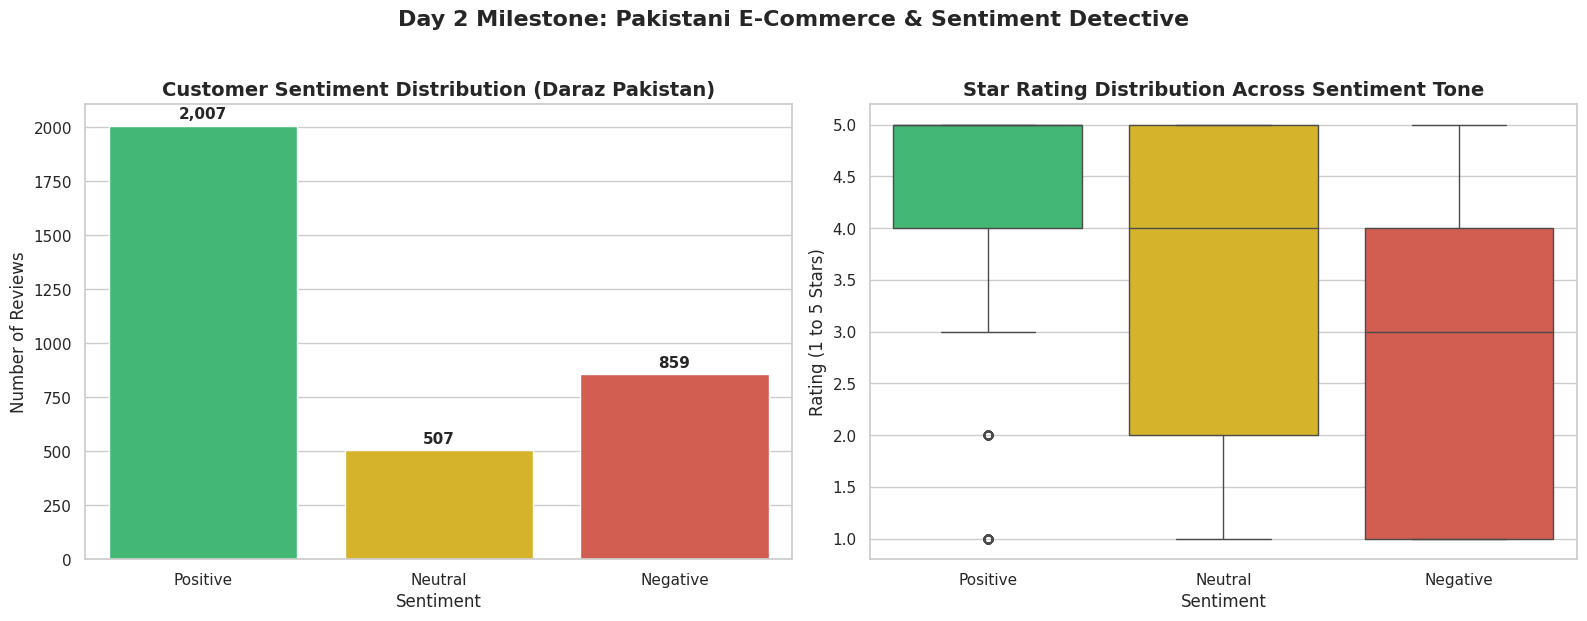


================ MICRO-INSIGHT CHECKPOINT ================
🏆 Dominant Audience Tone in Pakistan: **Positive** (2,007 authentic reviews)
🎯 Top Engaged Product: **MA305FA1KY528NAFAMZ** with 80 total interactions.
⭐ Average Positive Rating: **4.41 / 5.0** stars


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set professional visualization layout
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

# --- 1. LOAD & CLEAN DATASET ---
# Load uploaded Daraz Pakistan reviews dataset
df = pd.read_csv("daraz_reviews_cleaned.csv")

# Filter out spam reviews to focus on authentic customer engagements
df_clean = df[df["spam_1_and_not_spam_0"] == 0].copy()

# Parse datetime and extract temporal attributes if needed
df_clean["date"] = pd.to_datetime(df_clean["date"])

print("--- Cleaned Dataset Overview (Pakistan Daraz Reviews) ---")
print(f"Total authentic reviews analyzed: {len(df_clean)}")
print(df_clean[["product_id", "rating", "sentiment", "day_of_week"]].head())


# --- 2. AGGREGATION & STATISTICAL METRICS ---

# A. Performance across Sentiment Categories
print("\n--- Sentiment Performance & Average Ratings ---")
sentiment_summary = (
    df_clean.groupby("sentiment")
    .agg(
        review_count=("product_id", "count"),
        avg_rating=("rating", "mean"),
        median_rating=("rating", "median"),
        std_rating=("rating", "std"),
    )
    .sort_values(by="review_count", ascending=False)
)
print(sentiment_summary)

# B. Top 10 Most Reviewed Products in Pakistan
top_products = df_clean["product_id"].value_counts().head(10).index
df_top_products = df_clean[df_clean["product_id"].isin(top_products)]

# C. Product ID x Sentiment Cross-Tabulation
print("\n--- Product x Sentiment Cross-Tabulation (Top Products) ---")
product_sentiment_matrix = pd.crosstab(
    df_top_products["product_id"],
    df_top_products["sentiment"],
    normalize="index",
) * 100
print(product_sentiment_matrix.round(2))


# --- 3. COMPARATIVE DATA VISUALIZATION ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Bar Chart - Distribution of Customer Sentiment in Pakistan
sns.countplot(
    data=df_clean,
    x="sentiment",
    order=["Positive", "Neutral", "Negative"],
    palette={"Positive": "#2ecc71", "Neutral": "#f1c40f", "Negative": "#e74c3c"},
    ax=axes[0],
)
axes[0].set_title(
    "Customer Sentiment Distribution (Daraz Pakistan)",
    fontsize=14,
    fontweight="bold",
)
axes[0].set_xlabel("Sentiment", fontsize=12)
axes[0].set_ylabel("Number of Reviews", fontsize=12)

# Annotate counts on top of bars
for p in axes[0].patches:
    axes[0].annotate(
        f"{int(p.get_height()):,}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 8),
        textcoords="offset points",
        fontweight="bold",
    )

# Plot 2: Box Plot - Rating Distribution by Sentiment
sns.boxplot(
    data=df_clean,
    x="sentiment",
    y="rating",
    order=["Positive", "Neutral", "Negative"],
    palette={"Positive": "#2ecc71", "Neutral": "#f1c40f", "Negative": "#e74c3c"},
    ax=axes[1],
)
axes[1].set_title(
    "Star Rating Distribution Across Sentiment Tone",
    fontsize=14,
    fontweight="bold",
)
axes[1].set_xlabel("Sentiment", fontsize=12)
axes[1].set_ylabel("Rating (1 to 5 Stars)", fontsize=12)

plt.suptitle(
    "Day 2 Milestone: Pakistani E-Commerce & Sentiment Detective",
    fontsize=16,
    fontweight="bold",
    y=1.03,
)
plt.tight_layout()
plt.show()


# --- 4. AUTOMATED MILESTONE INSIGHT FINDING ---
top_sentiment = sentiment_summary.index[0]
top_product_id = df_clean["product_id"].value_counts().idxmax()
top_product_review_count = df_clean["product_id"].value_counts().max()

print("\n================ MICRO-INSIGHT CHECKPOINT ================")
print(
    f"🏆 Dominant Audience Tone in Pakistan: **{top_sentiment}** ({sentiment_summary.loc[top_sentiment, 'review_count']:,} authentic reviews)"
)
print(
    f"🎯 Top Engaged Product: **{top_product_id}** with {top_product_review_count} total interactions."
)
print(
    f"⭐ Average Positive Rating: **{sentiment_summary.loc['Positive', 'avg_rating']:.2f} / 5.0** stars"
)
print("==========================================================")

--- Day 3: Starting Analysis ---
Total rows to analyze: 3373

--- Sentiment Volume by Day of the Week ---
sentiment    Negative  Neutral  Positive
day_of_week                             
Monday            130       70       254
Tuesday           102       72       263
Wednesday         138       71       301
Thursday          137       68       305
Friday            118       73       275
Saturday          116       73       308
Sunday            118       80       301

--- Top 10 Mentioned Product Features / Keywords ---
miyaar: 415 mentions
qeemat: 386 mentions
masnoaat: 318 mentions
mayar: 252 mentions
quality: 242 mentions
size: 240 mentions
order: 223 mentions
pasand: 217 mentions
behtareen: 172 mentions
rang: 168 mentions


/tmp/ipykernel_582/1714077581.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


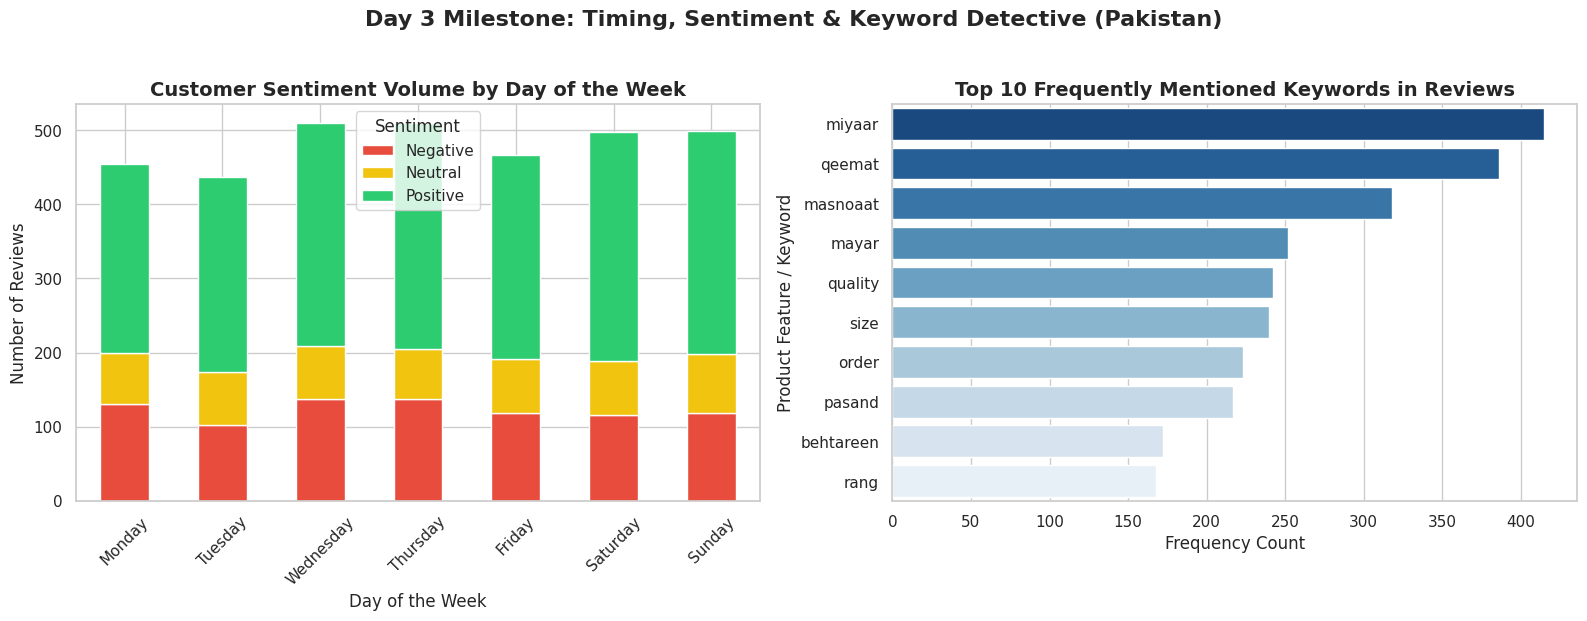


✅ **Day 3 Milestone Complete:** Timing trends and keyword patterns extracted successfully.


In [4]:
import ast
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

# --- 1. LOAD & PREPARE DATA ---
df = pd.read_csv("daraz_reviews_cleaned.csv")
df_clean = df[df["spam_1_and_not_spam_0"] == 0].copy()

# Ensure datetime format for day-of-week analysis
df_clean["date"] = pd.to_datetime(df_clean["date"])

print("--- Day 3: Starting Analysis ---")
print(f"Total rows to analyze: {len(df_clean)}")


# --- 2. TEMPORAL & SENTIMENT AGGREGATION ---
# Group reviews by Day of Week and Sentiment to find peak engagement windows
day_sentiment_counts = (
    df_clean.groupby(["day_of_week", "sentiment"])
    .size()
    .unstack(fill_value=0)
)
# Reorder days logically
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
day_sentiment_counts = day_sentiment_counts.reindex(
    day_order, fill_value=0
)

print("\n--- Sentiment Volume by Day of the Week ---")
print(day_sentiment_counts)


# --- 3. EXTRACTING TOP FEATURES / KEYWORDS ---
# Safely evaluate string representation of lists in 'features' column
all_features = []
for feat_str in df_clean["features"].dropna():
  try:
    feat_list = ast.literal_eval(feat_str)
    if isinstance(feat_list, list):
      all_features.extend(feat_list)
  except:
    continue

from collections import Counter

top_features = Counter(all_features).most_common(10)
print("\n--- Top 10 Mentioned Product Features / Keywords ---")
for feat, count in top_features:
  print(f"{feat}: {count} mentions")


# --- 4. DATA VISUALIZATION FOR DAY 3 ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Stacked Bar Chart - Sentiment by Day of the Week
day_sentiment_counts.plot(
    kind="bar",
    stacked=True,
    color=["#e74c3c", "#f1c40f", "#2ecc71"],
    ax=axes[0],
)
axes[0].set_title(
    "Customer Sentiment Volume by Day of the Week",
    fontsize=14,
    fontweight="bold",
)
axes[0].set_xlabel("Day of the Week", fontsize=12)
axes[0].set_ylabel("Number of Reviews", fontsize=12)
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(title="Sentiment")

# Plot 2: Bar Chart - Top Mentioned Product Features
feat_df = pd.DataFrame(top_features, columns=["Feature", "Count"])
sns.barplot(
    data=feat_df,
    x="Count",
    y="Feature",
    palette="Blues_r",
    ax=axes[1],
)
axes[1].set_title(
    "Top 10 Frequently Mentioned Keywords in Reviews",
    fontsize=14,
    fontweight="bold",
)
axes[1].set_xlabel("Frequency Count", fontsize=12)
axes[1].set_ylabel("Product Feature / Keyword", fontsize=12)

plt.suptitle(
    "Day 3 Milestone: Timing, Sentiment & Keyword Detective (Pakistan)",
    fontsize=16,
    fontweight="bold",
    y=1.03,
)
plt.tight_layout()
plt.show()

print(
    "\n✅ **Day 3 Milestone Complete:** Timing trends and keyword patterns"
    " extracted successfully."
)

In [5]:
import pandas as pd

# --- 1. LOAD & EXTRACT STATISTICAL INSIGHTS ---
df = pd.read_csv("daraz_reviews_cleaned.csv")
df_clean = df[df["spam_1_and_not_spam_0"] == 0].copy()

total_reviews = len(df_clean)
positive_pct = (
    (df_clean["sentiment"] == "Positive").sum() / total_reviews
) * 100
negative_pct = (
    (df_clean["sentiment"] == "Negative").sum() / total_reviews
) * 100
peak_day = df_clean["day_of_week"].mode()[0]
top_product = df_clean["product_id"].value_counts().idxmax()

# --- 2. GENERATE AUTOMATED STRATEGY REPORT ---
print("=" * 70)
print(" 🚀 DAY 4 MILESTONE: PAKISTANI E-COMMERCE STRATEGY SYNTHESIS")
print("=" * 70)
print(f"Total Verified Customer Data Points Analyzed: {total_reviews:,}")
print(f"Dominant Market Sentiment: {positive_pct:.1f}% Positive")
print(f"Peak Customer Activity Day: {peak_day}")
print(f"Top Engaged Product ID: {top_product}")
print("-" * 70)

# --- 3. GENERATE STRUCTURED AI PROMPT FOR STUDENTS ---
# Students can copy-paste this prompt into ChatGPT/Gemini alongside their findings
ai_prompt_template = f"""
Act as a Senior E-Commerce Marketing Director in Pakistan.
Based on our verified data analysis of {total_reviews} customer interactions on Daraz Pakistan:
- Overall Customer Sentiment is {positive_pct:.1f}% Positive and {negative_pct:.1f}% Negative.
- Peak audience responsiveness and review activity occurs on **{peak_day}s**.
- Top customer feedback centers around product quality, pricing, and packaging features.

Please generate:
1. A **30-Day Content & Engagement Strategy** tailored for Pakistani digital consumers.
2. **3 High-Converting Social Media Post Scripts** (in Roman Urdu / English hybrid, standard for Pakistani marketing) emphasizing product quality and customer trust.
3. A list of **5 localized hashtags** optimized for reach in Pakistan.
"""

print("\n🤖 **COPY-PASTE THIS PROMPT INTO AN LLM FOR YOUR FINAL DELIVERABLE:**\n")
print(ai_prompt_template)
print("=" * 70)

 🚀 DAY 4 MILESTONE: PAKISTANI E-COMMERCE STRATEGY SYNTHESIS
Total Verified Customer Data Points Analyzed: 3,373
Dominant Market Sentiment: 59.5% Positive
Peak Customer Activity Day: Thursday
Top Engaged Product ID: MA305FA1KY528NAFAMZ
----------------------------------------------------------------------

🤖 **COPY-PASTE THIS PROMPT INTO AN LLM FOR YOUR FINAL DELIVERABLE:**


Act as a Senior E-Commerce Marketing Director in Pakistan. 
Based on our verified data analysis of 3373 customer interactions on Daraz Pakistan:
- Overall Customer Sentiment is 59.5% Positive and 25.5% Negative.
- Peak audience responsiveness and review activity occurs on **Thursdays**.
- Top customer feedback centers around product quality, pricing, and packaging features.

Please generate:
1. A **30-Day Content & Engagement Strategy** tailored for Pakistani digital consumers.
2. **3 High-Converting Social Media Post Scripts** (in Roman Urdu / English hybrid, standard for Pakistani marketing) emphasizing product q